# Mining with MeerKAT EDR in the DP2 footprint

Selects the MeerKAT Mining-with-MeerKAT EDR images and L-band source catalog entries that fall within the Rubin DP2 footprint.

The footprint is built from the DP2 `Visit` table ([schema](https://sdm-schemas.lsst.io/dp2.html#Visit)). That table gives only the focal-plane centre of each visit, so each visit is approximated as a 1.75° radius cone (the LSSTCam field of view). Visits are accumulated into per-band HEALPix visit-count maps, and the footprint is defined as the sky where every band in `REQUIRED_BANDS` has at least `MIN_VISITS` visits. The result is stored as a MOC (Multi-Order Coverage map).

The two MeerKAT catalogs are read directly from their URLs. They are cached by astropy (in `~/.astropy/cache`) after the first download (the source catalog is ~160 MB). Use `clear_download_cache()` to force a fresh download.

In [1]:
# mocpy may not be in the RSP environment; install it into your user area if needed.
# After a fresh install, restart the kernel (Kernel > Restart Kernel) and run the notebook again.
try:
    import mocpy
except ImportError:
    %pip install --user --quiet mocpy

In [2]:
import os
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
import astropy.table as atpy
import astropy.units as u
from astropy.coordinates import Angle, Longitude, Latitude, SkyCoord
from mocpy import MOC
from astropy.wcs import WCS
from astropy.visualization.wcsaxes.frame import EllipticalFrame
from astropy.utils.data import download_file, clear_download_cache
from lsst.rsp import get_tap_service

In [3]:
DATA_DIR = os.getcwd()   # outputs (and the Visit table cache) go next to this notebook
LSSTCAM_RADIUS_DEG = 1.75   # LSSTCam field-of-view radius (same as lightcurvelynx)
NSIDE = 512                 # HEALPix resolution for the visit-count maps (~6.9 arcmin pixels)

# Footprint cut: sky where every band listed has at least this many visits.
# MIN_VISITS can be a single number, or a dict per band, e.g. {"g": 2, "r": 2, "z": 3}
REQUIRED_BANDS = ["g", "r", "z"]
MIN_VISITS = 2

os.makedirs(DATA_DIR, exist_ok=True)
VISIT_CACHE = os.path.join(DATA_DIR, "DP2_Visit.fits")

## Query the DP2 Visit table

In [4]:
if os.path.exists(VISIT_CACHE):
    visitTab = atpy.Table.read(VISIT_CACHE)
else:
    service = get_tap_service("tap")
    query = """SELECT visit, band, physical_filter, ra, dec, skyRotation, expTime, obsStartMJD
               FROM dp2.Visit"""
    job = service.submit_job(query)
    job.run()
    job.wait(phases=["COMPLETED", "ERROR"])
    job.raise_if_error()
    visitTab = job.fetch_result().to_table()
    job.delete()
    # TAP returns variable-length strings as object arrays, which FITS can't store
    for col in ["band", "physical_filter"]:
        visitTab[col] = np.array(visitTab[col], dtype=str)
    visitTab.write(VISIT_CACHE, overwrite=True)

visitTab.convert_bytestring_to_unicode()   # FITS cache returns band names as bytes
visitTab = visitTab[np.isfinite(visitTab["ra"]) & np.isfinite(visitTab["dec"])]
print(f"{len(visitTab)} visits")
bands, counts = np.unique(visitTab["band"], return_counts=True)
print("Visits per band:", {str(b): int(n) for b, n in zip(bands, counts)})

28698 visits
Visits per band: {'g': 4166, 'i': 7959, 'r': 4856, 'u': 1964, 'y': 3944, 'z': 5809}


## Per-band visit-count maps

Each visit adds 1 to every HEALPix pixel whose centre lies within 1.75° of the visit centre. This is an approximation: it ignores chip gaps and the square shape of the focal plane, and the counts include every visit in the table, whatever its quality.

In [5]:
npix = hp.nside2npix(NSIDE)
vecs = hp.ang2vec(np.array(visitTab["ra"]), np.array(visitTab["dec"]), lonlat=True)
radiusRad = np.radians(LSSTCAM_RADIUS_DEG)

countMaps = {}
for band in np.unique(visitTab["band"]):
    counts = np.zeros(npix, dtype=np.int32)
    for v in vecs[visitTab["band"] == band]:
        counts[hp.query_disc(NSIDE, v, radiusRad, nest=True)] += 1
    countMaps[str(band)] = counts

pixArea = hp.nside2pixarea(NSIDE, degrees=True)
for band, counts in countMaps.items():
    print(f"{band}: {np.sum(counts > 0) * pixArea:7.0f} deg^2 covered, median depth {np.median(counts[counts > 0]):.0f} visits")

g:    6151 deg^2 covered, median depth 4 visits
i:   12075 deg^2 covered, median depth 4 visits
r:    6101 deg^2 covered, median depth 3 visits
u:    3007 deg^2 covered, median depth 2 visits
y:    9060 deg^2 covered, median depth 3 visits
z:   10653 deg^2 covered, median depth 3 visits


## Footprint cut

Change `REQUIRED_BANDS` / `MIN_VISITS` in the config cell (or call `footprintMOC()` directly) to change the definition of usable sky. Re-running this cell is quick, because the count maps are already built.

In [6]:
def mocFromMask(mask):
    """MOC made from the HEALPix pixels (nested, NSIDE) where mask is True."""
    ipix = np.where(mask)[0].astype(np.uint64)
    order = hp.nside2order(NSIDE)
    return MOC.from_healpix_cells(ipix, np.full(len(ipix), order, dtype=np.uint8), max_depth=order)

def footprintMOC(requiredBands, minVisits):
    """MOC of the sky where every band in requiredBands has at least minVisits visits (int, or dict per band)."""
    if isinstance(minVisits, int):
        minVisits = {b: minVisits for b in requiredBands}
    mask = np.ones(npix, dtype=bool)
    for b in requiredBands:
        if b not in countMaps:
            raise ValueError(f"No visits in band {b!r}; available bands: {list(countMaps)}")
        mask &= countMaps[b] >= minVisits[b]
    return mocFromMask(mask)

mocAny = mocFromMask(np.sum(list(countMaps.values()), axis=0) > 0)   # any coverage at all, for comparison
moc = footprintMOC(REQUIRED_BANDS, MIN_VISITS)

sqDeg = 4 * np.pi * (180 / np.pi)**2
print(f"Any-band DP2 coverage: {mocAny.sky_fraction * sqDeg:.0f} deg^2")
print(f"Footprint after cut ({'+'.join(REQUIRED_BANDS)}, min visits {MIN_VISITS}): {moc.sky_fraction * sqDeg:.0f} deg^2")
moc.save(os.path.join(DATA_DIR, "DP2_footprint_moc.fits"), format="fits", overwrite=True)

Any-band DP2 coverage: 15603 deg^2
Footprint after cut (g+r+z, min visits 2): 3191 deg^2


## Select MeerKAT EDR images and sources inside the footprint

In [7]:
EDR_URL = "https://extragalactic.phys.wits.ac.za/mining-with-meerkat/EDR/data/"

def getTabInDP2(url, RACol, decCol):
    """Download (or read from the astropy cache) the catalog at url, and return the rows within the DP2 footprint."""
    tab = atpy.Table.read(download_file(url, cache=True, show_progress=False))
    hitMask = moc.contains_lonlat(Angle(tab[RACol], unit="deg"), Angle(tab[decCol], unit="deg"))
    print(f"{os.path.basename(url)}: {hitMask.sum()} / {len(tab)} in DP2")
    return tab[hitMask]

In [8]:
imagesTab = getTabInDP2(EDR_URL + "images_EDR.fits", RACol="centre_RADeg", decCol="centre_decDeg")
imagesTab.write(os.path.join(DATA_DIR, "InDP2_images_EDR.fits"), overwrite=True)

sourcesTab = getTabInDP2(EDR_URL + "survey_catalog_L_EDR.fits", RACol="RA", decCol="DEC")
sourcesTab.write(os.path.join(DATA_DIR, "InDP2_survey_catalog_L_EDR.fits"), overwrite=True)

images_EDR.fits: 12 / 141 in DP2
survey_catalog_L_EDR.fits: 19586 / 296942 in DP2


## Footprint map with MeerKAT EDR image positions

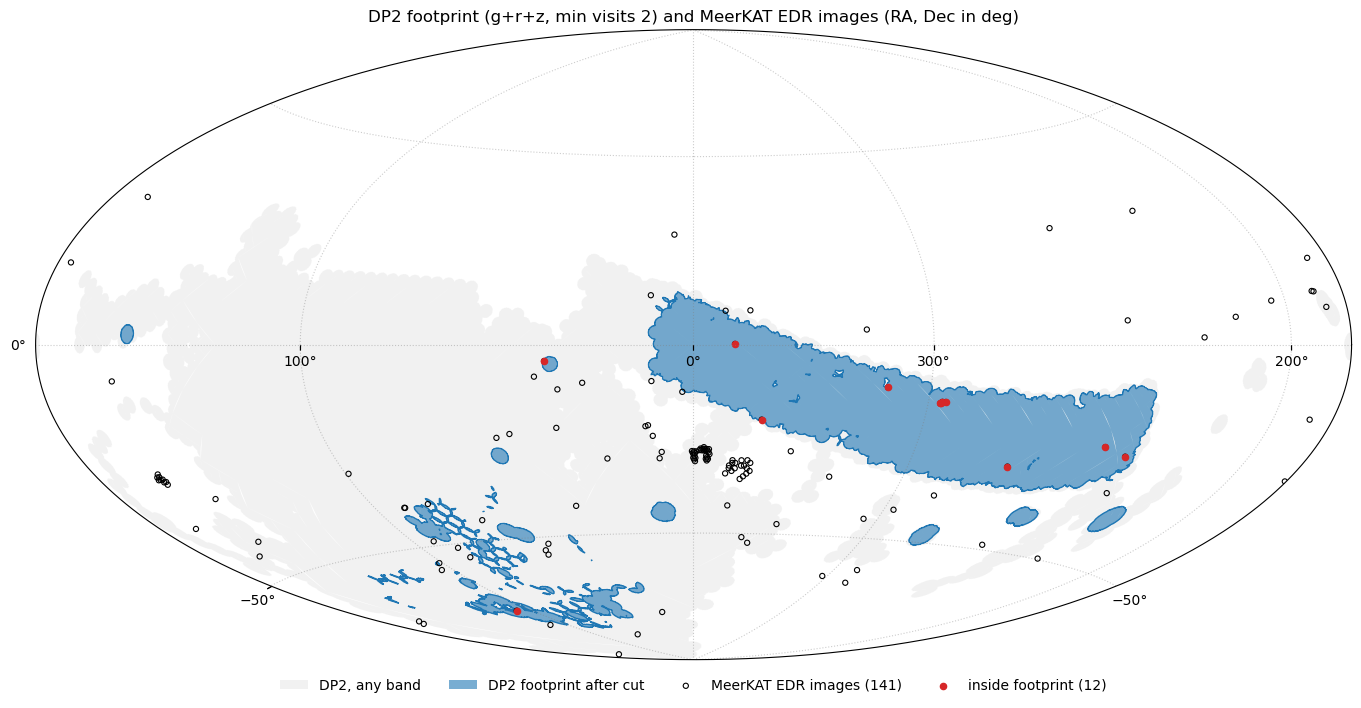

In [11]:
allImagesTab = atpy.Table.read(download_file(EDR_URL + "images_EDR.fits", cache=True, show_progress=False))

# Full-sky Aitoff WCS whose pixel grid just encloses the projected sky (4*sqrt(2) x 2*sqrt(2) radians)
cdelt = 0.1  # deg per pixel
nx, ny = int(np.ceil(4 * np.sqrt(2) * 180 / np.pi / cdelt)), int(np.ceil(2 * np.sqrt(2) * 180 / np.pi / cdelt))
wcs = WCS(naxis=2)
wcs.wcs.ctype = ["RA---AIT", "DEC--AIT"]
wcs.wcs.crval = [0, 0]
wcs.wcs.crpix = [nx / 2 + 0.5, ny / 2 + 0.5]
wcs.wcs.cdelt = [-cdelt, cdelt]
wcs.pixel_shape = (nx, ny)

fig = plt.figure(figsize=(14, 7.5))
ax = fig.add_axes([0.03, 0.09, 0.94, 0.84], projection=wcs, frame_class=EllipticalFrame)
ax.set_xlim(-0.5, nx - 0.5); ax.set_ylim(-0.5, ny - 0.5)
mocAny.fill(ax=ax, wcs=wcs, alpha=0.3, fill=True, facecolor="lightgrey", edgecolor="none", label="DP2, any band")
moc.fill(ax=ax, wcs=wcs, alpha=0.6, fill=True, facecolor="tab:blue", edgecolor="none", label="DP2 footprint after cut")
moc.border(ax=ax, wcs=wcs, color="tab:blue")
world = ax.get_transform("world")
ax.scatter(allImagesTab["centre_RADeg"], allImagesTab["centre_decDeg"], transform=world,
           s=14, facecolors="none", edgecolors="black", linewidths=0.8,
           label=f"MeerKAT EDR images ({len(allImagesTab)})")
ax.scatter(imagesTab["centre_RADeg"], imagesTab["centre_decDeg"], transform=world,
           s=20, color="tab:red", label=f"inside footprint ({len(imagesTab)})")
ax.coords.grid(True, color="grey", alpha=0.4, linestyle=":")
ax.coords[0].set_format_unit(u.deg); ax.coords[0].set_major_formatter("d")
ax.coords[1].set_major_formatter("d")
ax.coords[0].set_axislabel(""); ax.coords[1].set_axislabel("")
ax.set_title(f"DP2 footprint ({'+'.join(REQUIRED_BANDS)}, min visits {MIN_VISITS}) and MeerKAT EDR images (RA, Dec in deg)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=4, frameon=False)
fig.savefig(os.path.join(DATA_DIR, "DP2_footprint_MeerKAT_EDR.png"), dpi=150, bbox_inches="tight")
plt.show()